## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


- answer: The estimated ATE is about -0.010, or -1.0 percentage point. Survival is about 24.2% for Invasive and 25.2% for Conservative. Based only on these sample rates, I would choose Conservative, but the difference is small and does not show a clear benefit for either group.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
np.random.seed(42)  # Keep the results the same when rerunning.

## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

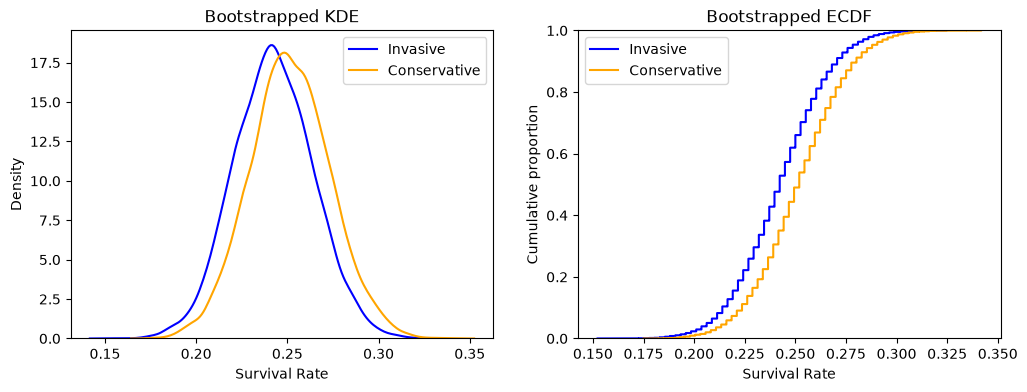

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Cumulative proportion')

ax[0].legend()
ax[1].legend()
plt.show()

- answer: The two curves overlap a lot. Conservative is slightly farther to the right, meaning a slightly higher survival rate. The difference between groups is small compared with the spread of the bootstrap results.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

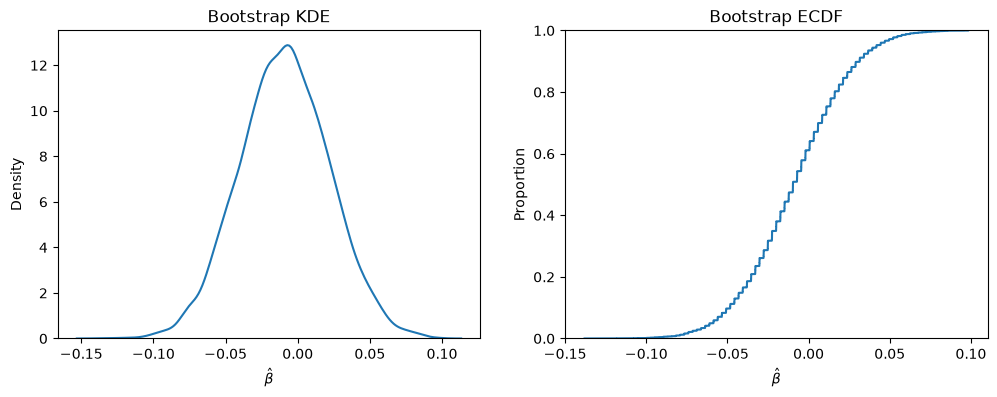

Smallest bootstrap ATE: -0.138
Largest bootstrap ATE: 0.098


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()

print("Smallest bootstrap ATE:", round(min(ate), 3))
print("Largest bootstrap ATE:", round(max(ate), 3))


- answer: Yes, the ATE is roughly bell-shaped and centered near -0.010. The bootstrap values range from about -0.138 to 0.098, or -13.8 to 9.8 percentage points. This is the range we saw in the samples, not a limit on the true effect.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05861613  0.04184003]
95% CI: [-0.06899895  0.05212281]
99% CI: [-0.08947079  0.07272159]


- answer: Zero is inside the 90%, 95%, and 99% confidence intervals. We fail to reject a zero treatment effect at all three levels. This does not prove the treatments have the same effect.

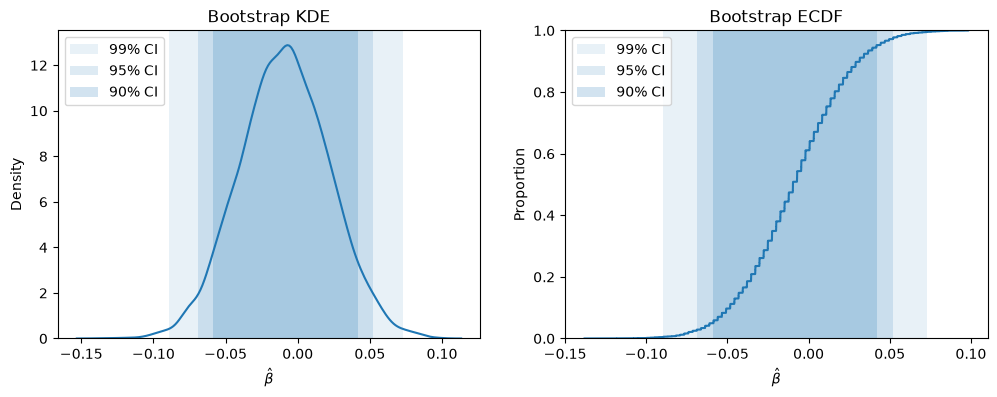

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()
plt.show()


**6.** What have we learned about inserting balloons into hearts?

- answer: In this dataset, the invasive group does not have clearly better survival than the conservative group. The small observed difference could be due to sampling variation. These data alone do not establish that the invasive treatment helps or harms survival.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## Part 2 answers

### 1. Load and summarize the data

- answer: I treat success as the desired outcome (avoiding progression to diabetes). A success is 1 and a failure is 0, so the mean is the success rate.

In [8]:
diabetes = pd.read_csv('./data/diabetes.csv')
diabetes['success'] = (diabetes['outcome'] == 'success').astype(int)

print(pd.crosstab(diabetes['treatment'], diabetes['outcome']))
print('Success rates:')
print(diabetes.groupby('treatment')['success'].mean())

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143
Success rates:
treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64


- answer: Metformin has a success rate of 48.3%, rosiglitazone 61.4%, and lifestyle changes 53.4%. Rosiglitazone has the highest sample success rate.

### 2. Bootstrap each group 10,000 times

In [9]:
np.random.seed(42)
R = 10000

met = diabetes.loc[diabetes['treatment'] == 'met', 'success']
rosi = diabetes.loc[diabetes['treatment'] == 'rosi', 'success']
lifestyle = diabetes.loc[diabetes['treatment'] == 'lifestyle', 'success']

met_rates = []
rosi_rates = []
lifestyle_rates = []

for i in range(R):
    met_rates.append(met.sample(frac=1, replace=True).mean())
    rosi_rates.append(rosi.sample(frac=1, replace=True).mean())
    lifestyle_rates.append(lifestyle.sample(frac=1, replace=True).mean())

### 3. Plot the group results

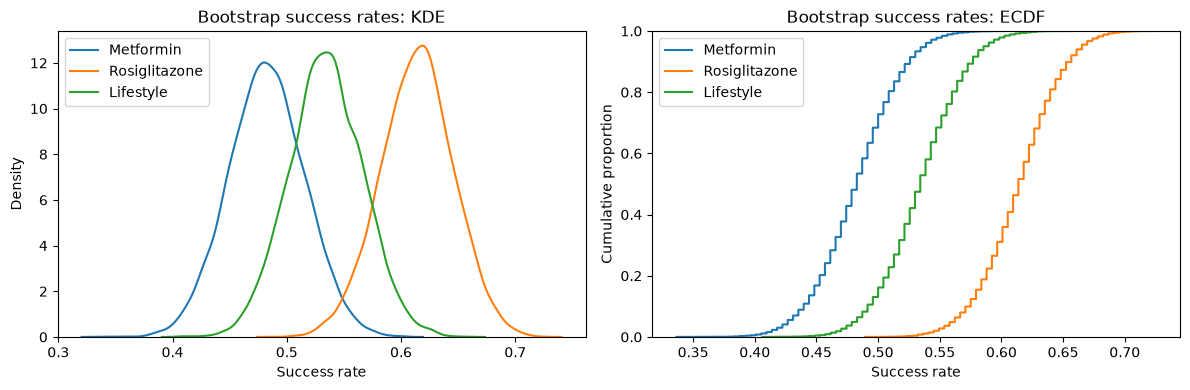

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(met_rates, label='Metformin', ax=ax[0])
sns.kdeplot(rosi_rates, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(lifestyle_rates, label='Lifestyle', ax=ax[0])
ax[0].set_title('Bootstrap success rates: KDE')
ax[0].set_xlabel('Success rate')
ax[0].legend()

sns.ecdfplot(met_rates, label='Metformin', ax=ax[1])
sns.ecdfplot(rosi_rates, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(lifestyle_rates, label='Lifestyle', ax=ax[1])
ax[1].set_title('Bootstrap success rates: ECDF')
ax[1].set_xlabel('Success rate')
ax[1].set_ylabel('Cumulative proportion')
ax[1].legend()

plt.tight_layout()
plt.show()

- answer: Rosiglitazone is farthest to the right, lifestyle is in the middle, and metformin is farthest to the left. This means rosiglitazone has the highest estimated success rate. The distributions overlap, especially lifestyle with the other groups.

### 4. Compare each pair

- answer: Each difference is the first group minus the second group. A positive value favors the first group; a negative value favors the second group.

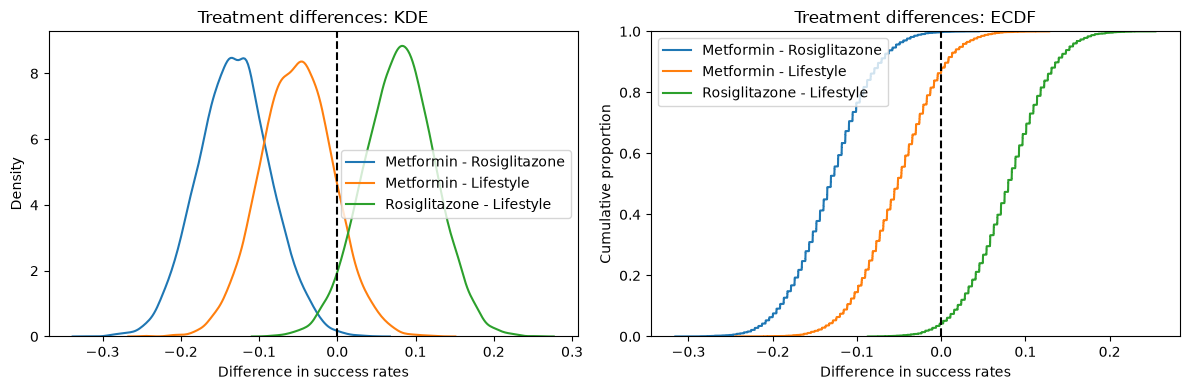

In [11]:
met_rosi = []
met_lifestyle = []
rosi_lifestyle = []

for i in range(R):
    met_rosi.append(met_rates[i] - rosi_rates[i])
    met_lifestyle.append(met_rates[i] - lifestyle_rates[i])
    rosi_lifestyle.append(rosi_rates[i] - lifestyle_rates[i])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(met_rosi, label='Metformin - Rosiglitazone', ax=ax[0])
sns.kdeplot(met_lifestyle, label='Metformin - Lifestyle', ax=ax[0])
sns.kdeplot(rosi_lifestyle, label='Rosiglitazone - Lifestyle', ax=ax[0])
ax[0].set_title('Treatment differences: KDE')
ax[0].set_xlabel('Difference in success rates')
ax[0].axvline(0, color='black', linestyle='--')
ax[0].legend()

sns.ecdfplot(met_rosi, label='Metformin - Rosiglitazone', ax=ax[1])
sns.ecdfplot(met_lifestyle, label='Metformin - Lifestyle', ax=ax[1])
sns.ecdfplot(rosi_lifestyle, label='Rosiglitazone - Lifestyle', ax=ax[1])
ax[1].set_title('Treatment differences: ECDF')
ax[1].set_xlabel('Difference in success rates')
ax[1].set_ylabel('Cumulative proportion')
ax[1].axvline(0, color='black', linestyle='--')
ax[1].legend()

plt.tight_layout()
plt.show()

### 5. Confidence intervals

- answer: I use 95% percentile bootstrap confidence intervals because the question does not specify a confidence level.

In [12]:
ci_met_rosi = np.quantile(met_rosi, [0.025, 0.975])
ci_met_lifestyle = np.quantile(met_lifestyle, [0.025, 0.975])
ci_rosi_lifestyle = np.quantile(rosi_lifestyle, [0.025, 0.975])

print('95% confidence intervals (first group minus second group):')
print('Metformin - Rosiglitazone:', np.round(ci_met_rosi, 3))
print('Metformin - Lifestyle:', np.round(ci_met_lifestyle, 3))
print('Rosiglitazone - Lifestyle:', np.round(ci_rosi_lifestyle, 3))

95% confidence intervals (first group minus second group):
Metformin - Rosiglitazone: [-0.221 -0.041]
Metformin - Lifestyle: [-0.142  0.039]
Rosiglitazone - Lifestyle: [-0.01   0.169]


- answer: Only the metformin versus rosiglitazone interval leaves out zero. It is negative, so rosiglitazone has a higher success rate than metformin at the 5% significance level. The other two intervals include zero. Rosiglitazone has the highest sample rate, but we can't honestly say it is better than lifestyle changes. 

### 6. Short report

| Treatment | Participants | Successes | Success rate |
|---|---:|---:|---:|
| Metformin | 232 | 112 | 48.3% |
| Rosiglitazone | 233 | 143 | 61.4% |
| Lifestyle | 234 | 125 | 53.4% |

| Comparison (first minus second) | Difference | 95% confidence interval |
|---|---:|---:|
| Metformin - Rosiglitazone | -13.1 percentage points | -22.1 to -4.1 percentage points |
| Metformin - Lifestyle | -5.1 percentage points | -14.2 to 3.9 percentage points |
| Rosiglitazone - Lifestyle | 8.0 percentage points | -1.0 to 16.9 percentage points |

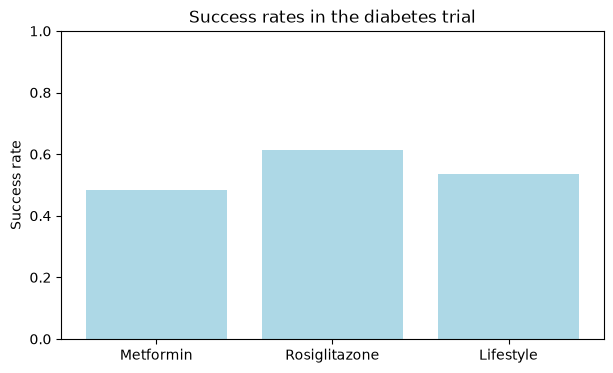

In [13]:
plt.figure(figsize=(7, 4))
plt.bar(['Metformin', 'Rosiglitazone', 'Lifestyle'],
        [met.mean(), rosi.mean(), lifestyle.mean()], color='lightblue')
plt.title('Success rates in the diabetes trial')
plt.ylabel('Success rate')
plt.ylim(0, 1)
plt.show()

The trial compared three ways to help people with pre-diabetes avoid developing diabetes: metformin, rosiglitazone, and lifestyle changes. There were 699 participants. I counted a recorded success as avoiding diabetes, following the lab description. Rosiglitazone had the highest success rate at 61.4%, followed by lifestyle changes at 53.4% and metformin at 48.3%. The tables and chart above show these results.

To check how much these results might vary, I took 10,000 bootstrap samples from each group. Each sample kept the original group's size and allowed participants to be selected more than once. I then found the differences in success rates and used the middle 95% of those differences as confidence intervals.

Rosiglitazone did better than metformin by about 13 percentage points. The 95% interval for metformin minus rosiglitazone was -22.1 to -4.1 percentage points, which leaves out zero. This supports a difference between those treatments. Lifestyle changes did better than metformin by about 5 percentage points, and rosiglitazone did better than lifestyle by about 8 points. Both of those intervals include zero, so neither difference is statistically significant at the 5% level. These are separate comparisons without an adjustment for multiple testing.

Based on success rates alone, the results favor rosiglitazone over metformin. Lifestyle changes also look promising, but the data do not clearly show a difference between lifestyle and either medication. Metformin had the lowest success rate, but that does not mean it has no benefit: this trial did not include an untreated group. Before recommending any of these options, we would also need to consider side effects, cost, and how long the benefits last, but those details are not in this dataset.